# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary. 

Answer: 

This is a supervised machine learning regression problem. The goal is to use historical used-car listings to identify features that influence vehicle prices and predict the price of a used car based on attributes such as manufacturer, year, mileage, condition, and transmission. Model performance will be evaluated using metrics such as R², MAE, and RMSE.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

Answer:

1. Inspect the dataset's dimensions, column names, data types, and sample rows to understand what information is available.
2. Use descriptive statistics and visualizations to examine numerical features, such as price, year, and odometer, and identify distributions, outliers, and unusual values.
3. Check for missing values, duplicate records, inconsistent categories, and invalid values, such as negative prices or mileage.
4. Explore categorical features, including manufacturer, condition, fuel type, transmission, and vehicle type, to understand their distributions and identify inconsistencies.
5. Analyze relationships between vehicle prices and potential predictors using correlation analysis, scatterplots, and comparisons across categories.
6. Investigate potential data quality issues and determine how to handle them, including removing duplicates, addressing missing values, and treating outliers.
7. Use the findings to refine the business understanding by identifying which features may be most useful for predicting used-car prices and informing pricing decisions.

### Data Exploration (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
cars = pd.read_csv('/Users/rue/Desktop/Berkeley Extension/Practical_Application_2/practical_application_II_starter/data/vehicles.csv')

In [3]:
# Datasets dimensions, column names, data types, and sample rows
print("cars shape:", cars.shape)
print("cars columns:", cars.columns)
print("cars dtypes:", cars.dtypes)
cars.sample(5)

cars shape: (426880, 18)
cars columns: Index(['id', 'region', 'price', 'year', 'manufacturer', 'model', 'condition',
       'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN',
       'drive', 'size', 'type', 'paint_color', 'state'],
      dtype='str')
cars dtypes: id                int64
region              str
price             int64
year            float64
manufacturer        str
model               str
condition           str
cylinders           str
fuel                str
odometer        float64
title_status        str
transmission        str
VIN                 str
drive               str
size                str
type                str
paint_color         str
state               str
dtype: object


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
49266,7314949929,reno / tahoe,8523,2013.0,chevrolet,impala,NaN,NaN,gas,114784.0,clean,automatic,2G1WC5E34D1240396,NaN,full-size,sedan,NaN,ca
205038,7305556516,kalamazoo,16960,2018.0,ford,escape,NaN,4 cylinders,gas,52411.0,clean,automatic,1FMCU9GD5JUD06051,4wd,NaN,SUV,white,mi
46738,7312252456,redding,17990,2012.0,volkswagen,touareg tdi sport suv,good,6 cylinders,gas,93185.0,clean,other,WVGFK9BP2CD004871,NaN,NaN,other,white,ca
423641,7312322434,milwaukee,2300,2010.0,kia,forte,NaN,NaN,gas,117058.0,clean,automatic,KNAFU4A27A5040809,NaN,compact,sedan,NaN,wi
123068,7315172212,atlanta,2500,2001.0,lexus,es 300,good,6 cylinders,gas,168000.0,clean,automatic,NaN,NaN,NaN,NaN,blue,ga


The dataset contains 426,880 rows and 18 columns. It includes vehicle attributes such as manufacturer, condition, model year, odometer reading, and transmission, along with the target variable, price. These features may help explain differences in used-car prices and support the development of a regression model.

In [4]:
# Check for missing values
cars.isnull().sum()

# Group and count rows by number of missing features
missing_counts = cars.isnull().sum(axis=1).value_counts().sort_index()

missing_df = pd.DataFrame({
    'missing_features': range(19),
    'number_of_rows': missing_counts.reindex(range(19), fill_value=0).values
})

missing_df

,missing_features,number_of_rows
0,0,34868
1,1,78259
2,2,99854
3,3,91251
4,4,46728
5,5,21196
6,6,19246
7,7,30443
8,8,4279
9,9,125


In [5]:
# Percentage of rows with nonmissing features
print(round(1 - (missing_df.iloc[1:, 1].sum()/missing_df.iloc[:,1].sum()),3)*100)

# Percentage of rows missing exactly 2 features
print(round((missing_df.iloc[2, 1] / missing_df.iloc[:, 1].sum()) * 100, 2))

# Percentage of rows missing 50% of more features
print(round((missing_df.iloc[9:19, 1].sum() / missing_df.iloc[:, 1].sum()) * 100, 2))

8.200000000000001
23.39
0.18


I examined missing values across columns and counted the number of missing features per row to assess data completeness. These results will help determine whether missing values should be removed or imputed during data preparation.

Approximately 8.2% of rows had no missing values. Approximately 23.39% of rows had exactly two missing features. Approximately 0.18% of rows were missing 50% or more of their features. The rows missing 50% or more features will be dropped during data cleaning due to the extent of missing information.

In [6]:
# Check for duplicate rows
print("Duplicate rows:\n", cars.duplicated().sum())
print("Duplicate feature IDs:\n", cars['id'].duplicated().sum())
print("Duplicate feature VINs:\n", cars['VIN'].duplicated().sum())
print("Rate of duplicate VIN rows:\n",
      round(cars['VIN'].duplicated().sum() / len(cars) * 100, 2), "%")
print("Duplicate rows minus feature ID:\n",
      cars.drop("id", axis=1).duplicated().sum())
print("Rate of duplicate rows minus ID:\n",
      round(cars.drop("id", axis=1).duplicated().sum() / len(cars) * 100, 2), "%")

print("\nMissing VINs:\n", cars['VIN'].isnull().sum())
print("Repeated VINs in rows with a VIN:\n",
      cars['VIN'].dropna().duplicated().sum())
print("Rate of repeated VINs in rows with a VIN:\n",
      round(cars['VIN'].dropna().duplicated().sum() / cars['VIN'].notna().sum() * 100, 2), "%")

# Check for invalid values
print(cars[['price', 'year', 'odometer']].describe())
print("Price <= 0:\n", (cars['price'] <= 0).sum())
print("Odometer < 0:\n", (cars['odometer'] < 0).sum())

Duplicate rows:
 0
Duplicate feature IDs:
 0
Duplicate feature VINs:
 308633
Rate of duplicate VIN rows:
 72.3 %
Duplicate rows minus feature ID:
 56202
Rate of duplicate rows minus ID:
 13.17 %

Missing VINs:
 161042
Repeated VINs in rows with a VIN:
 147592
Rate of repeated VINs in rows with a VIN:
 55.52 %
              price           year      odometer
count  4.268800e+05  425675.000000  4.224800e+05
mean   7.519903e+04    2011.235191  9.804333e+04
std    1.218228e+07       9.452120  2.138815e+05
min    0.000000e+00    1900.000000  0.000000e+00
25%    5.900000e+03    2008.000000  3.770400e+04
50%    1.395000e+04    2013.000000  8.554800e+04
75%    2.648575e+04    2017.000000  1.335425e+05
max    3.736929e+09    2022.000000  1.000000e+07
Price <= 0:
 32895
Odometer < 0:
 0


The dataset had no exact duplicate rows or duplicate IDs. However, 147,592 rows had repeated non-missing VINs, and 56,202 duplicate rows were identified after excluding the ID column. Potential data quality issues included 32,895 listings priced at \\$0 or less, a maximum price of \\$3.74 billion, and a maximum odometer reading of 10 million miles. No negative odometer readings were found. These issues will be addressed during data preparation.

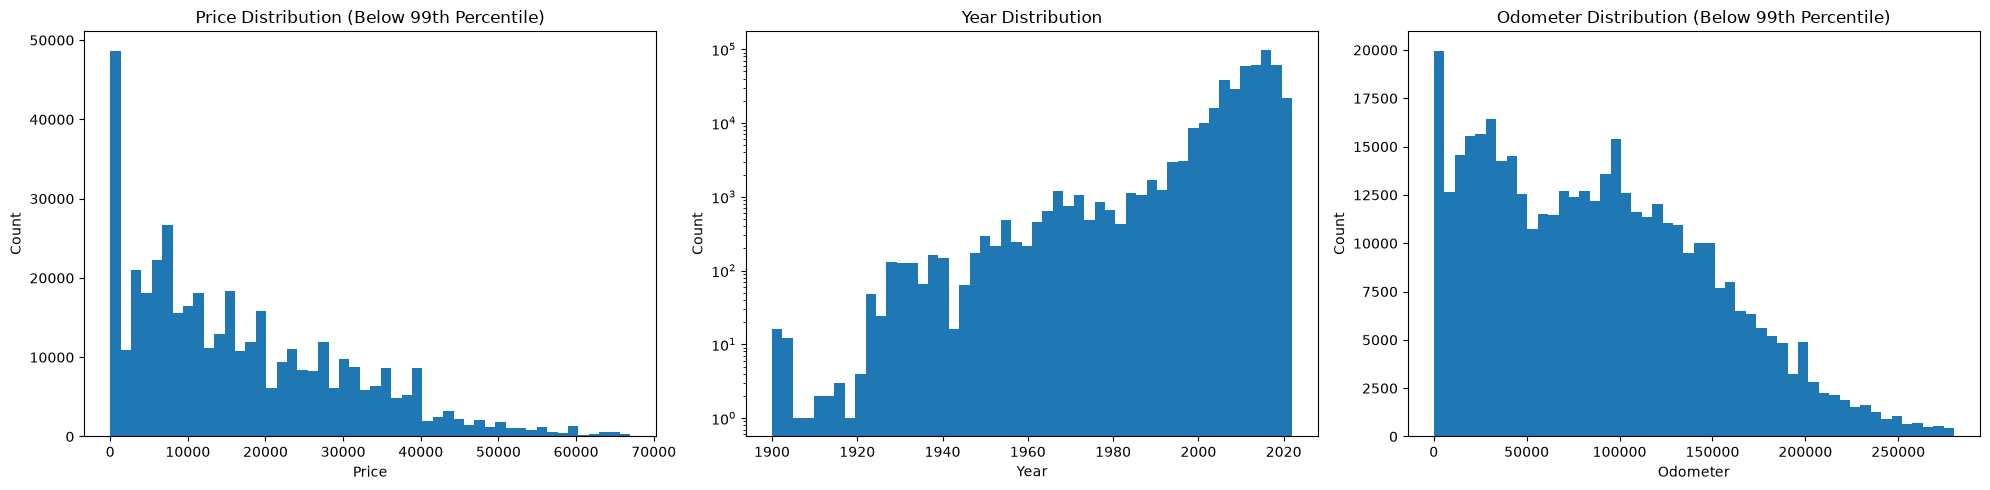

In [7]:
# Descriptive statistics and visualizations to examine numerical features

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# Price: exclude top 1% from the view
price_max = cars['price'].quantile(0.99)
ax[0].hist(cars.loc[cars['price'] <= price_max, 'price'], bins=50)
ax[0].set_title('Price Distribution (Below 99th Percentile)')
ax[0].set_xlabel('Price')
ax[0].set_ylabel('Count')

# Year
ax[1].hist(cars['year'].dropna(), bins=50)
ax[1].set_yscale('log')
ax[1].set_title('Year Distribution')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('Count')

# Odometer: exclude top 1% from the view
odo_max = cars['odometer'].quantile(0.99)
ax[2].hist(cars.loc[cars['odometer'] <= odo_max, 'odometer'], bins=50)
ax[2].set_title('Odometer Distribution (Below 99th Percentile)')
ax[2].set_xlabel('Odometer')
ax[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

The original price and odometer histograms were heavily skewed by extreme values. Limiting these visualizations to the 99th percentile made the distributions easier to interpret without removing data from the original dataset.

The price distribution showed approximately 50,000 vehicles listed at \\$0. Prices peaked at around \\$7,500, after which the number of listings gradually declined as prices increased. Above \\$40,000, the number of listings fell to approximately 2,000 per \\$1000 increase.

I used a logarithmic y-axis for the year distribution to make less frequent years easier to visualize. Vehicles manufactured before the 1950s had counts of approximately 100, while the 1980s through the 2000s had roughly 1,000 listings per year. Most vehicles were manufactured after the year 2000.

The odometer distribution showed that vehicles with zero miles were the most frequent. The next two highest counts were vehicles with approximately 35,000 and 100,000 miles. Listing counts gradually declined as mileage increased. Beyond 200,000 miles, the histogram bars fell below 2,500 listings per 10,000 increase in mileage.

In [8]:
# Identify categorical columns
cat_cols = cars.select_dtypes(include = 'object').columns

# Number of unique categories per column
cars[cat_cols].nunique()

# Frequency counts for most frequent categories in each column
for col in cat_cols:
    print(f'\n{col}')
    print(cars[col].value_counts(dropna=False).head(10))

# Frequency counts for least frequent categories in each column
for col in cat_cols:
    print(f'\n{col}')
    print(cars[col].value_counts(dropna=False).tail(10))

/var/folders/14/6njd_pqd0mx160qc42hp_6lr0000gn/T/ipykernel_37918/551280408.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = cars.select_dtypes(include = 'object').columns



region
region
columbus                    3608
jacksonville                3562
spokane / coeur d'alene     2988
eugene                      2985
fresno / madera             2983
orlando                     2983
omaha / council bluffs      2982
bend                        2982
new hampshire               2981
kennewick-pasco-richland    2981
Name: count, dtype: int64

manufacturer
manufacturer
ford         70985
chevrolet    55064
toyota       34202
honda        21269
nissan       19067
jeep         19014
ram          18342
NaN          17646
gmc          16785
bmw          14699
Name: count, dtype: int64

model
model
f-150             8009
NaN               5277
silverado 1500    5140
1500              4211
camry             3135
silverado         3023
accord            2969
wrangler          2848
civic             2799
altima            2779
Name: count, dtype: int64

condition
condition
NaN          174104
good         121456
excellent    101467
like new      21178
fair           6

The categorical analysis showed that Ford and Chevrolet were the most common manufacturers, with 70,985 and 55,064 listings, respectively. The F-150 was the most frequently listed model. Most vehicles with recorded condition were classified as “good” or “excellent,” while automatic transmission and gas fuel were the most common categories. However, several features had substantial missing data, particularly condition, cylinders, VIN, drive, size, and paint color. The dataset also contained rare categories, such as Morgan and Aston Martin manufacturers, and some regions and vehicle models had very few listings. These findings highlight the need to assess missing values, inconsistent categories, and rare categories during data preparation.

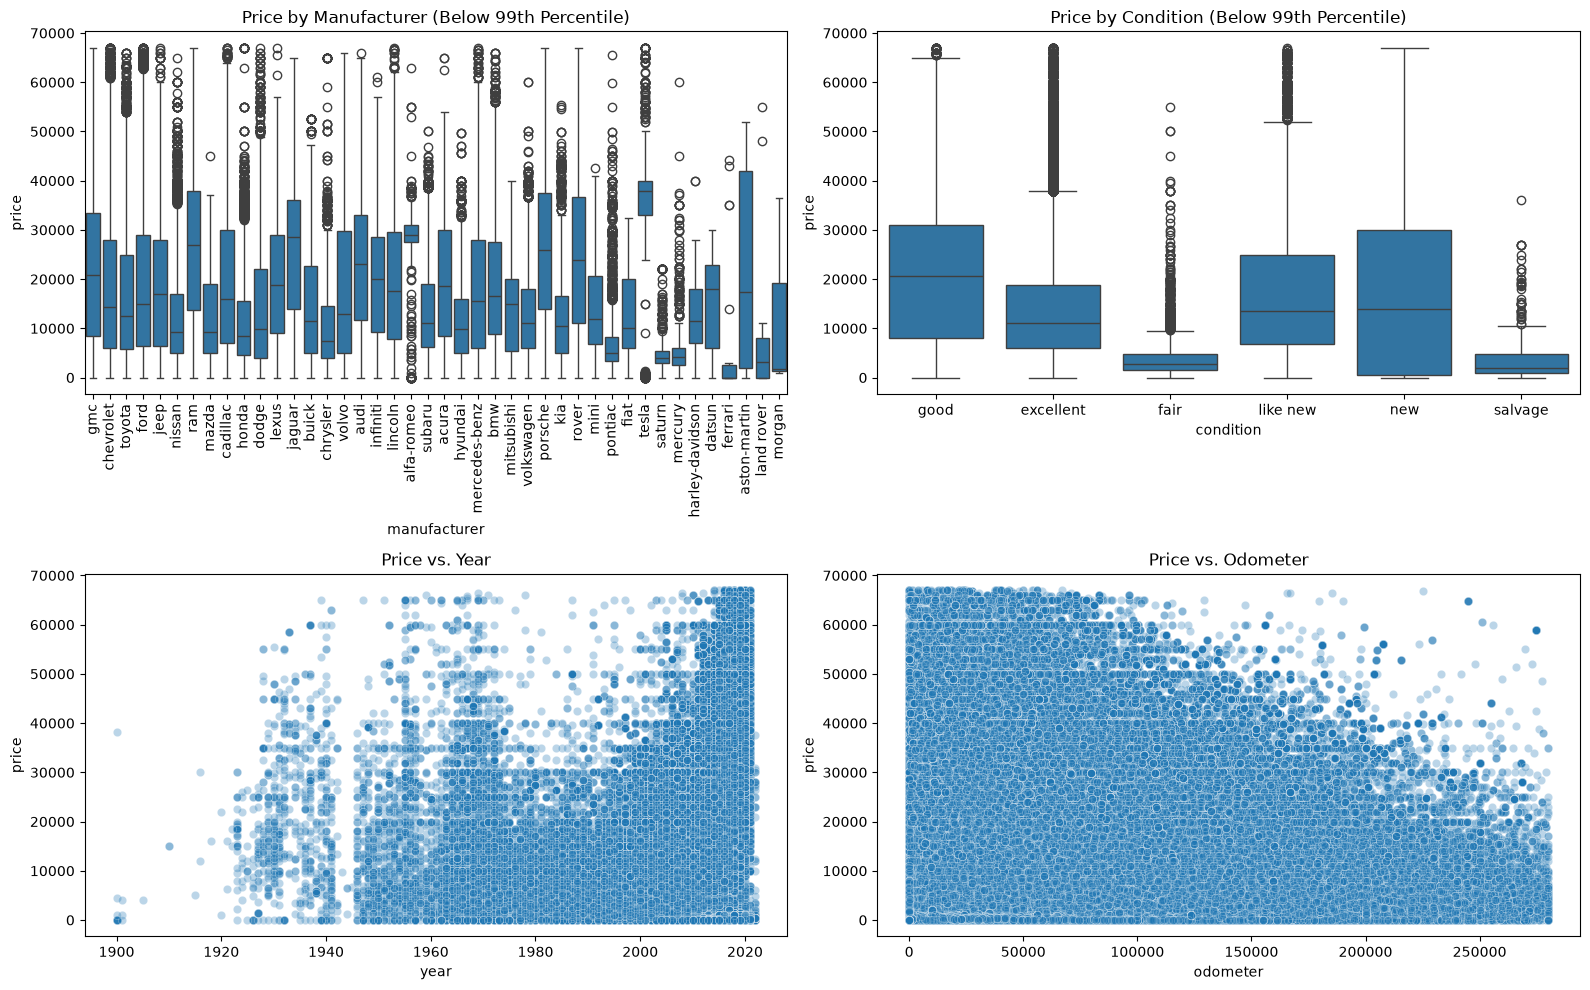

In [9]:
# Analyze relationships between vehicle prices and potential predictors

import seaborn as sns
import matplotlib.pyplot as plt

# Limit extreme values for visualization
price_max = cars['price'].quantile(0.99)
odo_max = cars['odometer'].quantile(0.99)

plot_cars = cars[
    (cars['price'] <= price_max) &
    (cars['odometer'] <= odo_max)
]

fig, ax = plt.subplots(2, 2, figsize=(16, 10))

# Manufacturer vs. price
sns.boxplot(data=plot_cars, x='manufacturer', y='price', ax=ax[0, 0])
ax[0, 0].tick_params(axis='x', rotation=90)
ax[0, 0].set_title('Price by Manufacturer (Below 99th Percentile)')

# Condition vs. price
sns.boxplot(data=plot_cars, x='condition', y='price', ax=ax[0, 1])
ax[0, 1].set_title('Price by Condition (Below 99th Percentile)')

# Year vs. price
sns.scatterplot(data=plot_cars, x='year', y='price', alpha=0.3, ax=ax[1, 0])
ax[1, 0].set_title('Price vs. Year')

# Odometer vs. price
sns.scatterplot(data=plot_cars, x='odometer', y='price', alpha=0.3, ax=ax[1, 1])
ax[1, 1].set_title('Price vs. Odometer')

plt.tight_layout()
plt.show()

I examined the relationships between asking price and four vehicle features: odometer reading, model year, manufacturer, and condition.

Odometer: Vehicles with odometer readings above 100,000 miles generally showed a negative relationship between mileage and asking price. As mileage increased, asking prices tended to decrease. This is an inverse relationship, although the trend may not be perfectly linear.

Year: Vehicles manufactured after 1980 generally showed higher asking prices as model year increased, although prices varied considerably for newer vehicles. Some vehicles manufactured between 1940 and 1960 had higher asking prices than vehicles from later decades. These may include vintage or classic cars, whose prices can reflect rarity, collectibility, and condition rather than age alone.

Manufacturer: I used a box plot to compare asking-price distributions across manufacturers. Most manufacturers had central price distributions ranging approximately from \\$6,000 to \\$40,000, although prices varied by brand. The interquartile ranges were relatively similar for many manufacturers, while observations above the upper quartile indicated higher-priced listings. Manufacturer-level price differences may reflect differences in vehicle type, brand positioning, and model availability.

Condition: I used a box plot to compare asking prices across vehicle-condition categories. Listings classified as *new* showed no visible outliers, while *like new*, *excellent*, and *fair* had numerous high-price outliers. The *good* category had the highest mean asking price, while *fair* and *salvage* had the lowest means, both below $5,000. These findings suggest an association between reported condition and asking price, although outliers and differences in vehicle types may influence the results.

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

* Tasks:
  * Loaded the Craigslist used cars dataset (426,880 rows, 18 columns) and inspected missing values and data types.
  * Removed duplicate listings: rows with a valid 17-character VIN were deduplicated on VIN, price, year, odometer and manufacturer, and rows without a valid VIN on price, year, manufacturer, odometer and state.
  * Dropped unneeded columns: id, VIN, size (72% missing) and region (~400 unique values, redundant with state).
  * Dropped rows missing key fields: year, manufacturer, model and odometer.
  * Filtered outliers: price \\$500 to \\$100,000, year 1990 to 2026, odometer 1 to 500,000 miles.
  * Cleaned cylinders: extracted the number from the text, set electric vehicles to 0, filled the remaining gaps with the manufacturer and fuel median (then the overall median), and rounded to whole numbers.
  * Filled missing values in condition, fuel, title_status, transmission, drive, type and paint_color with “unknown”.
Converted year to integer, then ran a final duplicate removal and validation.

* Observations:
  * About 13% of rows were exact duplicates once id was ignored, because sellers repost the same listing under new IDs.
  * The VIN duplicate rate of 72% was misleading, because the 161,041 missing VINs were counted as duplicates of each other. Among the 265,838 rows that had a VIN, 55.5% were repeats.
  * Size (72%), condition (41%), cylinders (42%), drive (31%) and paint_color (30%) had the most missing data.
  * Price and odometer contained unrealistic values (ex. $0 prices and extreme mileage) that would have skewed any analysis.
  * Dedupe, dropna and the outlier filters removed 221162 rows in total (51.8% of the original data).

* Outputs:
  * A cleaned dataset with 205718 rows and 13 columns.
  * Zero missing values and zero duplicate rows in the final validation.
  * Correct data types (year and cylinders as integers, price as int, odometer as float, the rest categorical text).

In [10]:
# 1. Deduplicate: 
print("Duplicate VINs:", cars['VIN'].duplicated().sum())
print("VIN duplicate rate:", round((cars['VIN'].duplicated().sum() / 426880)*100, 2),"%")


valid = cars["VIN"].astype(str).str.fullmatch(r"[A-HJ-NPR-Z0-9]{17}", case=False)

with_vin = cars[valid].drop_duplicates(
    subset=["VIN", "price", "year", "odometer", "manufacturer"]
)

no_vin = cars[~valid].drop_duplicates(
    subset=["price", "year", "manufacturer", "odometer", "state"]
)

cars = pd.concat([with_vin, no_vin]).drop(columns=["id", "VIN"])
print("After dedupe:", len(cars))

Duplicate VINs: 308633
VIN duplicate rate: 72.3 %
After dedupe: 250233


To address duplicate listings, I separated vehicles with valid 17-character VINs from those with invalid or missing VINs. For vehicles with valid VINs, I removed duplicates based on VIN, price, year, odometer, and manufacturer. For vehicles without valid VINs, I used price, year, manufacturer, odometer, and state to identify duplicate records. I then combined the two groups and removed the `id` and `VIN` columns before modeling.

In [11]:
# 2. Drop columns you don't need
cars = cars.drop(columns=["size", "region", "model"])   # size: 72% missing; region: redundant with state; model: ~30,000 messy values

In [12]:
# 3. Drop rows missing key fields or missing more than 50% of their columns
cars = cars.dropna(subset=["year","manufacturer","odometer"])
cars = cars.dropna(thresh=len(cars.columns) / 2)
print("after dropping missing key fields:", len(cars))

after dropping missing key fields: 236562


In [13]:
# 4. Filter bad values
cars = cars[cars["price"].between(500, 100_000)]
cars = cars[cars["year"].between(1990, 2026)]
cars = cars[cars["odometer"].between(1, 500_000)]
print("after filtering outliers:", len(cars))

after filtering outliers: 205940


In [14]:
# 5. Cylinders: convert text to numbers and fill missing values
cars["cylinders"] = cars["cylinders"].str.extract(r"(\d+)").astype(float)

# Electric cars have no cylinders
cars.loc[cars["fuel"] == "electric", "cylinders"] = 0

# Fill by manufacturer + fuel median, then fall back to the overall median
cars["cylinders"] = cars["cylinders"].fillna(
    cars.groupby(["manufacturer", "fuel"])["cylinders"].transform("median")
)
cars["cylinders"] = cars["cylinders"].fillna(cars["cylinders"].median())

# Round to whole numbers (medians can give 5.5, 7.0, etc.)
cars["cylinders"] = cars["cylinders"].round().astype(int)

In [15]:
# 6. Fill remaining gaps in categorical columns with "unknown"
for col in ["condition","fuel","title_status","transmission","drive","type","paint_color"]:
    cars[col] = cars[col].fillna("unknown")

In [16]:
# 7. Tidy types
cars["year"] = cars["year"].astype(int)
print("final:", len(cars))

final: 205940


In [17]:
# 8. Final dedupe
cars = cars.drop_duplicates()
print("After final dedupe:", len(cars))

After final dedupe: 205718


In [19]:
# 9. Final validation
print("Missing values:\n", cars.isna().sum())
print("Duplicate rows:", cars.duplicated().sum())
print("Data types:\n", cars.dtypes)

cars.shape

Missing values:
 price           0
year            0
manufacturer    0
condition       0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
type            0
paint_color     0
state           0
dtype: int64
Duplicate rows: 0
Data types:
 price             int64
year              int64
manufacturer        str
condition           str
cylinders         int64
fuel                str
odometer        float64
title_status        str
transmission        str
drive               str
type                str
paint_color         str
state               str
dtype: object


(205718, 13)

### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

In [20]:
# Spliting, pipelines, tuning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Scaling and encoding
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor

# Regression metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score 


In [21]:
# train/test split
X = cars.drop('price', axis = 1)
y = cars['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.25,
    random_state = 42
)

In [22]:
# Create transformer and scaler
transformer = ColumnTransformer([
    ("encode", OneHotEncoder(handle_unknown = "ignore"),['manufacturer','condition','fuel','title_status','transmission','drive','type','paint_color','state']),
    ("scale", StandardScaler(), ["year","odometer","cylinders"])
])

In [23]:
# Pipeline and GridSearchCV
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=20000),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42),
}

params = {
    "LinearRegression": {},   # nothing to tune
    "Ridge": {
        "model__alpha": [0.1, 1, 10, 100],
    },
    "Lasso": {
        "model__alpha": [0.01, 0.1, 1, 10],
    },
    "DecisionTreeRegressor": {
        "model__max_depth": [5, 10, 20, None],
        "model__min_samples_leaf": [1, 5, 20],
    },
}

In [24]:
results = {}
best_models = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocess", transformer),
        ("model", model)
    ])
    grid = GridSearchCV(pipe, params[name], cv=3, scoring="r2", n_jobs=-1)
    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    y_pred = grid.predict(X_test)
    results[name] = {
        "best_params": grid.best_params_,
        "Train R2": r2_score(y_train, grid.predict(X_train)),
        "Test R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": root_mean_squared_error(y_test, y_pred),
    }

pd.DataFrame(results).T

/opt/anaconda3/envs/berkeley/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.531449e+10, tolerance: 1.772e+09
  model = cd_fast.sparse_enet_coordinate_descent(
/opt/anaconda3/envs/berkeley/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.536042e+10, tolerance: 1.776e+09
  model = cd_fast.sparse_enet_coordinate_descent(
/opt/anaconda3/envs/berkeley/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or con

,best_params,Train R2,Test R2,MAE,RMSE
LinearRegression,{},0.658832,0.654671,5167.305879,7756.601076
Ridge,{'model__alpha': 1},0.65881,0.654743,5167.288057,7755.792828
Lasso,{'model__alpha': 0.01},0.658832,0.654677,5167.250316,7756.539095
DecisionTreeRegressor,"{'model__max_depth': 20, 'model__min_samples_l...",0.791218,0.740656,4051.869694,6721.918782


In [25]:
# Get the feature names and importances for the best tree
best_tree = best_models["DecisionTreeRegressor"]
feature_names = best_tree.named_steps["preprocess"].get_feature_names_out()

tree_imp = pd.Series(
    best_tree.named_steps["model"].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(tree_imp.head(15))

scale__year                       0.524463
scale__cylinders                  0.158357
scale__odometer                   0.100660
encode__fuel_diesel               0.080199
encode__drive_fwd                 0.025340
encode__drive_4wd                 0.019018
encode__title_status_clean        0.004427
encode__manufacturer_porsche      0.004305
encode__type_pickup               0.004031
encode__paint_color_unknown       0.003964
encode__drive_unknown             0.003950
encode__type_sedan                0.003717
encode__manufacturer_tesla        0.003690
encode__manufacturer_ram          0.003576
encode__manufacturer_chevrolet    0.003334
dtype: float64


In [26]:
# Get the feature names and coefficients for the best linear model
best_linear_model = best_models["LinearRegression"]
feature_names = best_linear_model.named_steps["preprocess"].get_feature_names_out()

linear_model_imp = pd.Series(
    best_linear_model.named_steps["model"].coef_,
    index=feature_names
).sort_values(ascending=False)

print(linear_model_imp.head(15))

encode__manufacturer_ferrari         52157.701022
encode__manufacturer_aston-martin    21907.313224
encode__manufacturer_tesla           19475.253295
encode__manufacturer_porsche         11187.793954
encode__fuel_diesel                   9136.055168
scale__year                           5623.104491
encode__condition_new                 4284.723769
encode__manufacturer_alfa-romeo       4003.890080
encode__title_status_lien             3000.324256
encode__type_pickup                   2981.210966
encode__state_wa                      2818.378571
encode__manufacturer_rover            2747.802216
encode__type_offroad                  2683.564675
encode__drive_4wd                     2655.417025
encode__type_convertible              2638.241768
dtype: float64


### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

##### Model Evaluation and Business Recommendations

The Decision Tree Regressor performed best among the four models evaluated, achieving a test R² of 0.741, MAE of approximately \\$4,052, and RMSE of approximately \\$6,722. This model outperformed Linear Regression, Ridge, and Lasso, suggesting that a nonlinear model better captures the relationships between vehicle features and asking prices. The MAE indicates that predictions differed from actual asking prices by approximately $4,052 on average, while the RMSE suggests that some predictions had substantially larger errors.

Feature importance analysis identified model year (52.4%), cylinders (15.8%), and odometer reading (10.1%) as the most influential predictors in the Decision Tree. These results suggest that vehicle age, engine characteristics, and mileage are important factors in estimating used-car prices. Manufacturer and other categorical features also contributed to predictions, indicating that pricing depends on more than mileage and age alone.

Before deployment, I would revisit data preparation to investigate extreme prices and odometer readings, assess the impact of duplicate listings, and confirm that missing values and unusual vehicle categories were handled appropriately. I would also evaluate model performance across different manufacturers and price ranges to determine whether the model performs consistently or is less accurate for certain vehicles. Overall, the Decision Tree provides useful insights into the drivers of used-car asking prices and a promising starting point for supporting dealership pricing decisions, but additional validation and refinement would be needed before relying on it in a business setting.

### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

# Used-Car Price Prediction Report

## Objective
The goal of this project was to identify the factors that influence used-car asking prices and develop a model to help dealerships make informed pricing and inventory decisions.

## Findings
Exploratory data analysis showed that newer vehicles generally had higher asking prices, while vehicles with higher odometer readings tended to have lower prices. Asking prices also varied by manufacturer and vehicle condition. Data quality checks identified missing values, repeated VINs, zero or negative prices, and unusually high prices and odometer readings that needed consideration during data preparation.

## Model Results
Four regression models were evaluated: Linear Regression, Ridge, Lasso, and Decision Tree. The Decision Tree performed best, achieving a test R² of 0.741, MAE of approximately \\$4,052, and RMSE of approximately \\$6,722. This means the model explained 74.1% of the variation in test-set asking prices, with predictions differing from actual asking prices by about \\$4,052 on average.

Feature importance analysis identified model year (52.4%), cylinders (15.8%), and odometer reading (10.1%) as the leading predictors. These results suggest that vehicle age, engine characteristics, and mileage are important considerations when estimating asking prices.

## Recommendations
Dealerships should compare vehicles with similar model years, mileage, manufacturers, and engine characteristics when setting prices. The Decision Tree can provide an initial price estimate to support these comparisons, but predictions should be considered alongside local market demand, vehicle condition, and competing listings.

## Conclusion
The Decision Tree was the strongest model tested and provides useful insights into used-car pricing. However, its prediction errors and the limitations of the dataset mean it should be used as a decision-support tool rather than a definitive pricing authority. Further validation on current listings and actual sale prices would help determine its effectiveness in real dealership settings.